## Redoing plots on same stile as Dirk's fist plot font size, spacing and size.

Others where slightly different but aspects and fonts where kept same to Fig. 5

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path

RESULTS = Path("Results")
FIGURES = Path("Figures_Paper")
FIGURES.mkdir(exist_ok=True)

# Load Monte Carlo results
mc_austin = pd.read_pickle(RESULTS / "mc_austin_50y.pkl")
mc_phoenix = pd.read_pickle(RESULTS / "mc_phoenix_50y.pkl")
mc_by_area = pd.read_pickle(RESULTS / "mc_by_area_50y.pkl")

In [26]:
# ============================================================
# GLOBAL PAPER FORMATTING — ALL FIGURES
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    # Fonts
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.title_fontsize": 9,

    # Lines and axes
    "axes.linewidth": 0.5,
    "lines.linewidth": 2.0,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 4,
    "ytick.major.size": 4,

    # Figure dimensions
    "figure.figsize": (3.4, 2.6),
    "figure.dpi": 120,

    # Saving
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # Legend
    "legend.frameon": True,
    "legend.framealpha": 0.9,

    # Grid
    "axes.grid": False,

    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "axes.labelpad": 2,
    "xtick.major.pad": 2,
    "ytick.major.pad": 2,
})

## Figure 5: Physical vs. performance-adjusted capacity

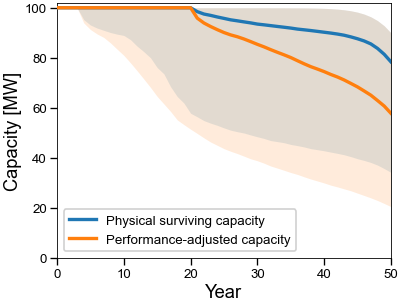

In [27]:
# ============================================================
# FIGURE 5 — Austin Monte Carlo capacity trajectories (50y)
# ============================================================

summary = (
    mc_austin.groupby("year")
    .agg(
        physical_p10=("available_capacity_MW_end",
                      lambda x: np.percentile(x, 10)),
        physical_p50=("available_capacity_MW_end", "median"),
        physical_p90=("available_capacity_MW_end",
                      lambda x: np.percentile(x, 90)),
        effective_p10=("effective_capacity_MW_end",
                       lambda x: np.percentile(x, 10)),
        effective_p50=("effective_capacity_MW_end", "median"),
        effective_p90=("effective_capacity_MW_end",
                       lambda x: np.percentile(x, 90))
    )
    .reset_index()
)

# Load 50-year simulation results
mc_austin = pd.read_pickle(RESULTS / "mc_austin_50y.pkl")

# Summarize Monte Carlo results
fig5_summary = (
    mc_austin.groupby("year")
    .agg(
        physical_p10=("available_capacity_MW_end",
                      lambda x: np.percentile(x, 10)),
        physical_p50=("available_capacity_MW_end", "median"),
        physical_p90=("available_capacity_MW_end",
                      lambda x: np.percentile(x, 90)),
        effective_p10=("effective_capacity_MW_end",
                       lambda x: np.percentile(x, 10)),
        effective_p50=("effective_capacity_MW_end", "median"),
        effective_p90=("effective_capacity_MW_end",
                       lambda x: np.percentile(x, 90))
    )
    .reset_index()
)

# Create figure — dimensions inherited from global settings
fig, ax = plt.subplots()

# Physical surviving capacity — uncertainty band
ax.fill_between(
    fig5_summary["year"],
    fig5_summary["physical_p10"],
    fig5_summary["physical_p90"],
    color="tab:blue",
    alpha=0.15,
    linewidth=0
)

# Performance-adjusted capacity — uncertainty band
ax.fill_between(
    fig5_summary["year"],
    fig5_summary["effective_p10"],
    fig5_summary["effective_p90"],
    color="tab:orange",
    alpha=0.15,
    linewidth=0
)

# Median trajectories
ax.plot(
    fig5_summary["year"],
    fig5_summary["physical_p50"],
    color="tab:blue",
    label="Physical surviving capacity",
    zorder=3
)

ax.plot(
    fig5_summary["year"],
    fig5_summary["effective_p50"],
    color="tab:orange",
    label="Performance-adjusted capacity",
    zorder=4
)

# Axes
ax.set_xlabel("Year")
ax.set_ylabel("Capacity [MW]")

ax.set_xlim(0, 50)
ax.set_ylim(0, 102)

ax.set_xticks(np.arange(0, 51, 10))
ax.set_yticks(np.arange(0, 101, 20))

# Legend
ax.legend(loc="lower left")

# Layout
fig.tight_layout(pad=0.5)

# Save
fig.savefig(FIGURES / "Fig05_capacity_50y.png")
fig.savefig(FIGURES / "Fig05_capacity_50y.pdf")

plt.show()

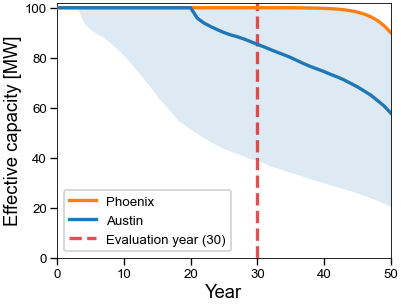

In [30]:
# ============================================================
# FIGURE 6 — Austin vs. Phoenix capacity trajectories (50y)
# ============================================================

# Load 50-year simulation results
mc_austin = pd.read_pickle(RESULTS / "mc_austin_50y.pkl")
mc_phoenix = pd.read_pickle(RESULTS / "mc_phoenix_50y.pkl")

# Summarize Monte Carlo results
def summarize_mc_capacity(mc):
    return (
        mc.groupby("year")["effective_capacity_MW_end"]
        .agg(
            median="median",
            p10=lambda x: np.percentile(x, 10),
            p90=lambda x: np.percentile(x, 90)
        )
        .reset_index()
    )

austin_summary = summarize_mc_capacity(mc_austin)
phoenix_summary = summarize_mc_capacity(mc_phoenix)

evaluation_year = 30

# Create figure — dimensions inherited from global settings
fig, ax = plt.subplots()

# Phoenix uncertainty band
ax.fill_between(
    phoenix_summary["year"],
    phoenix_summary["p10"],
    phoenix_summary["p90"],
    color="tab:orange",
    alpha=0.15,
    linewidth=0
)

# Austin uncertainty band
ax.fill_between(
    austin_summary["year"],
    austin_summary["p10"],
    austin_summary["p90"],
    color="tab:blue",
    alpha=0.15,
    linewidth=0
)

# Median trajectories
ax.plot(
    phoenix_summary["year"],
    phoenix_summary["median"],
    color="tab:orange",
    label="Phoenix",
    zorder=3
)

ax.plot(
    austin_summary["year"],
    austin_summary["median"],
    color="tab:blue",
    label="Austin",
    zorder=4
)

# Evaluation year — original red dashed line
ax.axvline(
    evaluation_year,
    color="tab:red",
    linestyle="--",
    linewidth=2.0,
    alpha=0.8,
    label=f"Evaluation year ({evaluation_year})"
)

# Axes
ax.set_xlabel("Year")
ax.set_ylabel("Effective capacity [MW]")

ax.set_xlim(0, 50)
ax.set_ylim(0, 102)

ax.set_xticks(np.arange(0, 51, 10))
ax.set_yticks(np.arange(0, 101, 20))

# Legend
ax.legend(loc="lower left")

# Layout
fig.tight_layout(pad=0.5)

# Save
fig.savefig(FIGURES / "Fig06_austin_vs_phoenix_50y.png")
fig.savefig(FIGURES / "Fig06_austin_vs_phoenix_50y.pdf")

plt.show()

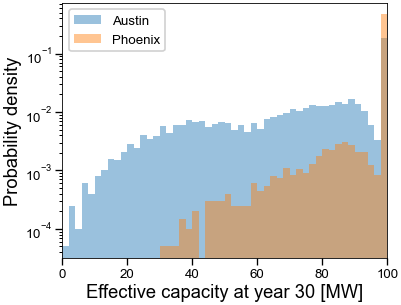

In [31]:
# ============================================================
# FIGURE 7 — Capacity distribution at year 30 (50y)
# ============================================================

# Load 50-year simulation results
mc_austin = pd.read_pickle(RESULTS / "mc_austin_50y.pkl")
mc_phoenix = pd.read_pickle(RESULTS / "mc_phoenix_50y.pkl")

evaluation_year = 30

# Extract effective capacity at evaluation year
austin_eval = mc_austin.loc[
    mc_austin["year"] == evaluation_year,
    "effective_capacity_MW_end"
]

phoenix_eval = mc_phoenix.loc[
    mc_phoenix["year"] == evaluation_year,
    "effective_capacity_MW_end"
]

# Create figure — dimensions inherited from global settings
fig, ax = plt.subplots()

# Shared histogram bins for direct comparison
bins = np.linspace(0, 100, 51)

ax.hist(
    austin_eval,
    bins=bins,
    density=True,
    alpha=0.45,
    color="tab:blue",
    label="Austin"
)

ax.hist(
    phoenix_eval,
    bins=bins,
    density=True,
    alpha=0.45,
    color="tab:orange",
    label="Phoenix"
)

# Axes
ax.set_yscale("log")

ax.set_xlabel(f"Effective capacity at year {evaluation_year} [MW]")
ax.set_ylabel("Probability density")

ax.set_xlim(0, 100)
ax.set_xticks(np.arange(0, 101, 20))

# Legend
ax.legend(loc="upper left")

# Layout
fig.tight_layout(pad=0.5)

# Save
fig.savefig(FIGURES / "Fig07_year30_distribution_50y.png")
fig.savefig(FIGURES / "Fig07_year30_distribution_50y.pdf")

plt.show()

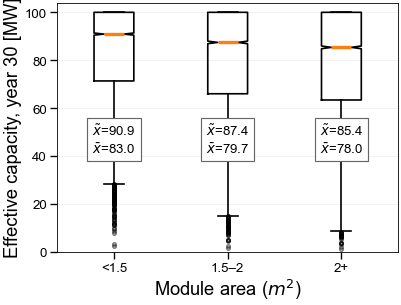

In [36]:
# ============================================================
# FIGURE 10 — Module area vs. effective capacity at year 30
# ============================================================

import pickle
import numpy as np
import matplotlib.pyplot as plt

# Load 50-year simulation results
with open(RESULTS / "mc_by_area_50y.pkl", "rb") as f:
    mc_by_area = pickle.load(f)

evaluation_year = 30

# Extract year-30 capacity by module area
# Maintain the intended category order
area_cases = [
    ("<1.5", 1.4),
    ("1.5-2", 1.75),
    ("2+", 2.1)
]


area_labels = ["<1.5", "1.5–2", "2+"]
area_data = []

for _, module_area in area_cases:
    matching = [
        df for df in mc_by_area.values()
        if np.isclose(df["module_area_m2"].iloc[0], module_area)
    ]

    if len(matching) != 1:
        raise ValueError(f"Could not uniquely identify module area {module_area} m²")

    values = matching[0].loc[
        matching[0]["year"] == evaluation_year,
        "effective_capacity_MW_end"
    ].dropna()

    area_data.append(values.to_numpy())

# Create figure — inherits global formatting
fig, ax = plt.subplots()

# Notched boxplots
ax.boxplot(
    area_data,
    tick_labels=area_labels,
    widths=0.35,
    notch=True,
    patch_artist=False,
    showfliers=True,
    medianprops=dict(color="tab:orange", linewidth=2),
    boxprops=dict(color="black", linewidth=1),
    whiskerprops=dict(color="black", linewidth=1),
    capprops=dict(color="black", linewidth=1),
    flierprops=dict(
        marker="o",
        markersize=2,
        markerfacecolor="none",
        markeredgecolor="black",
        alpha=0.5
    )
)

# Median (x-tilde) and mean (x-bar) annotations
for i, values in enumerate(area_data, start=1):
    median = np.median(values)
    mean = np.mean(values)

    annotation = (
        rf"$\tilde{{x}}$={median:.1f}" + "\n" +
        rf"$\bar{{x}}$={mean:.1f}"
    )

    ax.text(
        i, 47,
        annotation,
        ha="center",
        va="center",
        bbox=dict(
            facecolor="white",
            edgecolor="0.4",
            linewidth=0.7,
            pad=3
        )
    )

# Axes
ax.set_xlabel(r"Module area ($m^2$)")
ax.set_ylabel(f"Effective capacity, year {evaluation_year} [MW]")

ax.set_ylim(0, 104)
ax.set_yticks(np.arange(0, 101, 20))

# Light horizontal grid
ax.grid(axis="y", alpha=0.18, linewidth=0.5)

# Layout
fig.tight_layout(pad=0.5)

# Save
fig.savefig(FIGURES / "Fig10_module_area_boxplot_50y.png")
fig.savefig(FIGURES / "Fig10_module_area_boxplot_50y.pdf")

plt.show()